In [ ]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
DATA_PATH = r"/hour.csv"
FIG_DIR="graphs"
os.makedirs(FIG_DIR, exist_ok=True)

In [ ]:
#1. data upload and exploration

In [ ]:
df=pd.read_csv(DATA_PATH)
print(df.shape)
print(df.head())
print(df["cnt"].describe())

(17379, 17)
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  
count    17379.000000
mean       189.463088
std        181.387599
min          1.000000

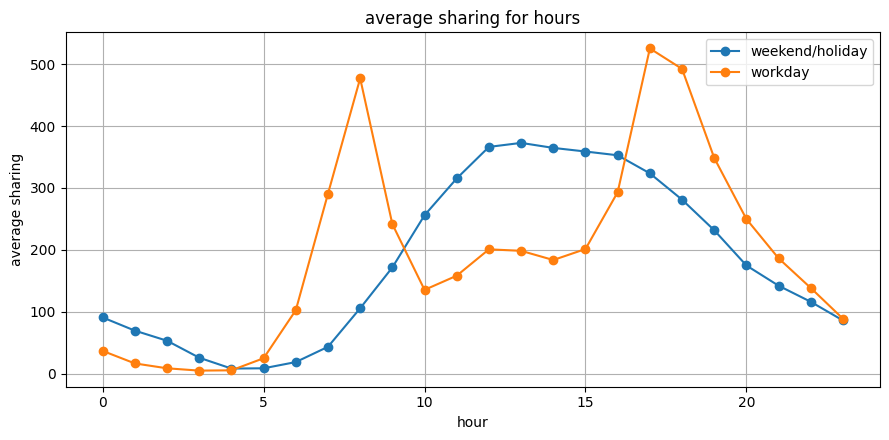

In [ ]:
#hourly average sharing(weekdays and weekends)
hourly=df.groupby(["hr","workingday"])["cnt"].mean().unstack()
hourly.columns=["weekend/holiday","workday"]
ax=hourly.plot(marker="o", figsize=(9,4.5), grid=True)
ax.set(title="average sharing for hours",
       xlabel="hour", ylabel="average sharing")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/hourly_sharing_table.png", dpi=150)
plt.show()

In [ ]:
#2. feature/target and train-test split

In [ ]:
#casual+registered=cnt
X=df.drop(columns=["instant", "dteday", "casual","registered","cnt"])
y=df["cnt"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
#3. model and training

In [ ]:
categ=["season", "mnth", "hr", "weekday", "weathersit"]
numer=["yr", "holiday","workingday", "temp", "atemp", "hum","windspeed"]
model=Pipeline([("prep", ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categ),
    ("num", StandardScaler(), numer)
])),
    ("lr", LinearRegression()),])
model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['season', 'mnth', 'hr',
                                                   'weekday', 'weathersit']),
                                                 ('num', StandardScaler(),
                                                  ['yr', 'holiday',
                                                   'workingday', 'temp',
                                                   'atemp', 'hum',
                                                   'windspeed'])])),
                ('lr', LinearRegression())])

In [ ]:
#4. model analysis: coefficients

In [ ]:
lr=model.named_steps["lr"]
coefs=pd.Series(lr.coef_,index=model.named_steps["prep"].get_feature_names_out())
print(f"intercept: {lr.intercept_}")
print(coefs.sort_values(ascending=False).head(8).round(1))
print(coefs.sort_values().head(8).round(1))

intercept: 28.179582945361716
cat__hr_17    382.7
cat__hr_18    342.5
cat__hr_8     316.2
cat__hr_19    235.9
cat__hr_16    225.8
cat__hr_12    176.5
cat__hr_13    172.1
cat__hr_7     172.0
dtype: float64
cat__weathersit_4   -127.6
cat__weathersit_3    -64.6
cat__hr_4            -39.7
cat__hr_3            -37.3
cat__hr_2            -27.2
cat__hr_5            -21.7
cat__hr_1            -16.8
num__hum             -15.8
dtype: float64


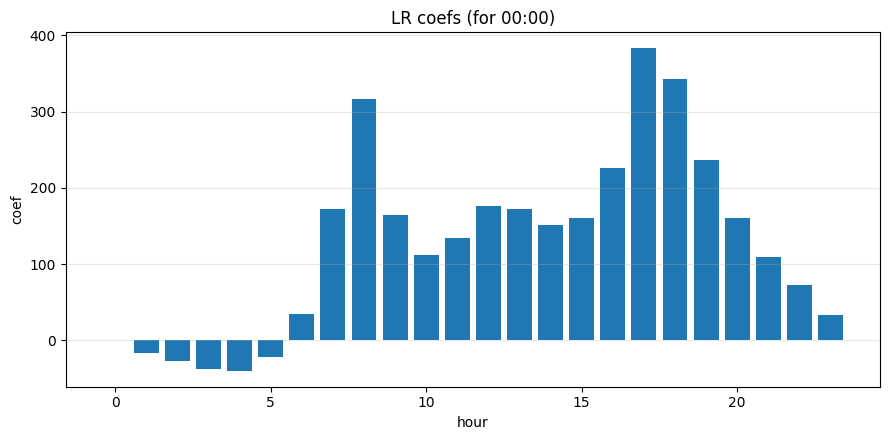

In [ ]:
#hour_coefficients
hour_coef=coefs[coefs.index.str.startswith("cat__hr_")]
hour_coef.index=hour_coef.index.str.replace("cat__hr_","").astype(int)
hour_coef=pd.concat([pd.Series({0:0.0}),hour_coef]).sort_index()

fig,ax=plt.subplots(figsize=(9,4.5))
ax.bar(hour_coef.index, hour_coef.values)
ax.set(title="LR coefs (for 00:00)",xlabel="hour", ylabel="coef")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lr_hour_coefs.png", dpi=150)

In [ ]:
#5 prediction

In [ ]:
y_pred_train=model.predict(X_train)
y_pred_test=model.predict(X_test)
comparison=X_test[["hr","workingday","weathersit","temp"]].assign(
    real=y_test, pred=y_pred_test.round(0), er=(y_test-y_pred_test).round(0))
print(comparison.head(10))


       hr  workingday  weathersit  temp  real   pred     er
12830  19           0           1  0.80   425  449.0  -24.0
8688   20           0           1  0.24    88  162.0  -74.0
7091    2           1           1  0.32     4    5.0   -1.0
12230  19           1           1  0.78   526  432.0   94.0
431     0           1           1  0.26    13  -69.0   82.0
1086    0           1           1  0.44    32  -25.0   57.0
11605  18           1           1  0.72   706  530.0  176.0
7983    7           0           1  0.26    26  148.0 -122.0
10391   2           1           1  0.50     2   60.0  -58.0
7046    5           1           1  0.42    21   30.0   -9.0


In [ ]:
# new scenarions. Normalization: temp=°C/41, atemp=°C/50, hum=%/100, windspeed=km/s/67
mut = dict(holiday=0, temp=20 / 41, atemp=20 / 50, hum=0.55, windspeed=10 / 67)
sce = pd.DataFrame({
    "workday 08:00, sunny": dict(season=2, yr=1, mnth=5, hr=8, weekday=3, workingday=1, weathersit=1, **mut),
    "workday 17:00, sunny": dict(season=2, yr=1, mnth=5, hr=17, weekday=3, workingday=1, weathersit=1, **mut),
    "Pazar 08:00, sunny": dict(season=2, yr=1, mnth=5, hr=8, weekday=0, workingday=0, weathersit=1, **mut),
    "workday 03:00, rainy": dict(season=1, yr=1, mnth=1, hr=3, holiday=0, weekday=2, workingday=1,
                                    weathersit=3, temp=8 / 41, atemp=6 / 50, hum=0.90, windspeed=25 / 67),
}).T[X.columns].astype(float)
print(pd.Series(model.predict(sce), index=sce.index).round(1))

workday 08:00, sunny    447.1
workday 17:00, sunny    513.6
Pazar 08:00, sunny      434.9
workday 03:00, rainy   -134.2
dtype: float64


In [ ]:
#6. evaluation

In [ ]:
def mtrcs (y_true, y_pred):
    return{"MAE: " : mean_absolute_error(y_true, y_pred),
           "RMSE: ":np.sqrt(mean_squared_error(y_true, y_pred)),
           "R2: ": r2_score(y_true, y_pred)}
reslt=pd.DataFrame({"train": mtrcs(y_train, y_pred_train),
                    "test":mtrcs(y_test, y_pred_test)}).T
print(reslt.round(4))
print(f"negative pred: {(y_pred_test < 0).sum()} / {len(y_pred_test)}")

         MAE:     RMSE:     R2: 
train  75.5574  101.9181  0.6871
test   74.1052  100.4460  0.6814
negative pred: 319 / 3476


In [ ]:
#visualization

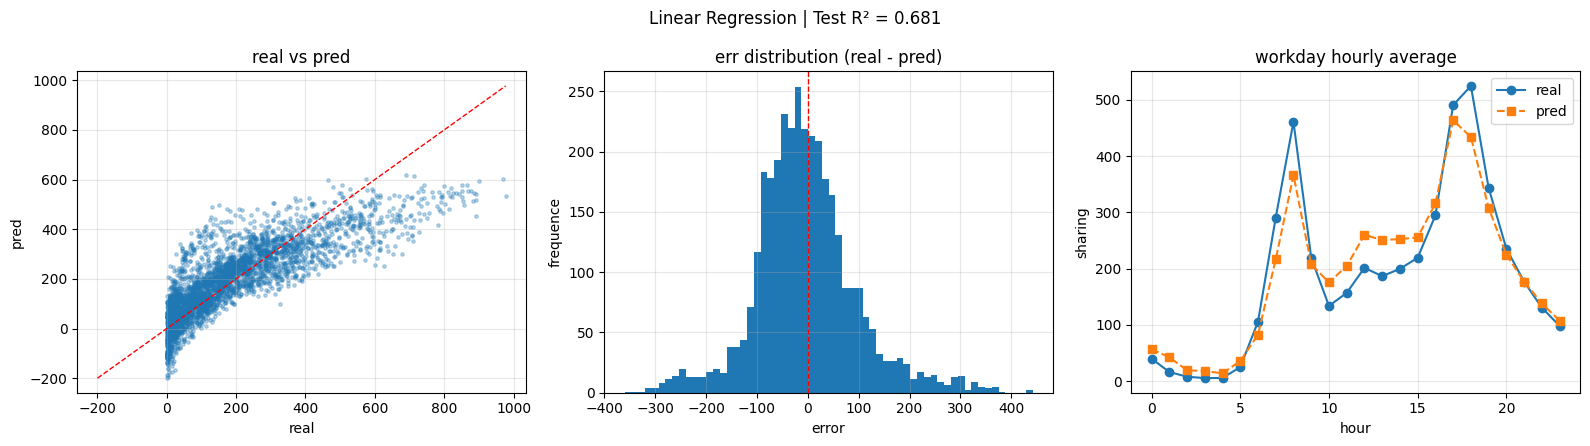

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(y_test, y_pred_test, s=6, alpha=0.3)
lim = [min(y_test.min(), y_pred_test.min()), y_test.max()]
axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set(title="real vs pred", xlabel="real", ylabel="pred")

axes[1].hist(y_test - y_pred_test, bins=60)
axes[1].axvline(0, color="r", ls="--", lw=1)
axes[1].set(title="err distribution (real - pred)", xlabel="error", ylabel="frequence")

is_gunu = (X_test.assign(real=y_test, pred=y_pred_test)
           .query("workingday == 1").groupby("hr")[["real", "pred"]].mean())
axes[2].plot(is_gunu.index, is_gunu["real"], "o-", label="real")
axes[2].plot(is_gunu.index, is_gunu["pred"], "s--", label="pred")
axes[2].set(title="workday hourly average", xlabel="hour", ylabel="sharing")
axes[2].legend()

for a in axes:
    a.grid(alpha=0.3)
fig.suptitle(f"Linear Regression | Test R² = {reslt.loc['test', 'R2: ']:.3f}")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lr_results.png", dpi=150)
plt.show()